# Final Streamflow Forecast — Stony Brook

CEE 306: Hydrology — Water and Climate | Spring 2026

Coursework portfolio version. The original code, model outputs, and team-written interpretations are retained; assignment instructions have been removed.

**Forecast Team Name:** `<HBO>`

**Names:** `<Sayfullo Saidov, Muhammad Omer, Wunnyuriti Ziblim>`

**Forecasted Dates:** May 5 - May 7

This notebook documents a three-day streamflow forecast for Stony Brook using observed hydrometeorological conditions, weather forecasts, evapotranspiration estimates, and a linear reservoir model. It was completed as a team forecasting exercise.

In [1]:
import pandas as pd
import numpy as np
import json, requests 
import matplotlib.pyplot as plt
import datetime

## Weather Forecast and Recent Streamflow Observations

In [2]:
## forecast for temperature and precipitation 
headers = { 
'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/71.0.3578.98 Safari/537.36', 
'Accept' : 'text/html,application/xhtml+xml,application/xml;q=0.9,*/*;q=0.8', 
'Accept-Language' : 'en-US,en;q=0.5', 
'Accept-Encoding' : 'gzip', 
'DNT' : '1', # Do Not Track Request Header 
'Connection' : 'close' }
url = requests.get("https://api.weather.gov/gridpoints/PHI/63,95/", headers=headers)

data_json = json.loads(url.text)

data = pd.DataFrame(columns=('DateTime','Precip [mm]','Temp [C]'))
for i in range(13):
    data.loc[i] = [data_json['properties']['quantitativePrecipitation']['values'][i]['validTime'], 
                   data_json['properties']['quantitativePrecipitation']['values'][i]['value'],
                   data_json['properties']['temperature']['values'][i]['value']]
 

data['DateTime'] = data['DateTime'].str.slice(stop=16)
data['cum_precip_mm'] = data['Precip [mm]'].cumsum()
data['Precip_ft'] = data['Precip [mm]']*0.00328084
data['Precip_in'] = data['Precip [mm]']*0.0393701
data['cum_precip_in'] = data['Precip_in'].cumsum()
data['cum_precip_ft'] = data['Precip_ft'].cumsum()
    
print('Forecasted Data')
print(data)

Forecasted Data
            DateTime Precip [mm]   Temp [C] cum_precip_mm Precip_ft Precip_in  \
0   2026-05-05T03:00           0  16.111111             0       0.0       0.0   
1   2026-05-05T06:00           0  15.555556             0       0.0       0.0   
2   2026-05-05T12:00           0  15.000000             0       0.0       0.0   
3   2026-05-05T18:00           0  14.444444             0       0.0       0.0   
4   2026-05-06T00:00           0  13.333333             0       0.0       0.0   
5   2026-05-06T06:00           0  13.888889             0       0.0       0.0   
6   2026-05-06T12:00       2.286  14.444444         2.286    0.0075      0.09   
7   2026-05-06T18:00       3.048  16.666667         5.334      0.01      0.12   
8   2026-05-07T00:00       0.762  19.444444         6.096    0.0025      0.03   
9   2026-05-07T06:00       0.254  21.666667          6.35  0.000833      0.01   
10  2026-05-07T12:00       0.508  23.888889         6.858  0.001667      0.02   
11  2026-05-

In [45]:
## now let's get past week of streamflow and precipitation - using the same url process as before
period = "P10D"
# agian, feel free to print and look at those URLs

# streamflow from Stony Brook
flow_url = "https://nwis.waterdata.usgs.gov/nwis/iv/?format=rdb&sites=01401000&period="+period+"&parameterCd=00060&siteStatus=all"
StonyBrook = pd.read_csv(flow_url, skiprows=28, sep='\t', header=None)
StonyBrook.columns = ["agency_cd","site_no","datetime_stony","tz_cd","flow_cfs","194689_00060_cd"]

# precip from Skillman
precip_url = "https://nwis.waterdata.usgs.gov/nwis/iv/?format=rdb&sites=402504074414201&period="+period+"&parameterCd=00045&siteStatus=all"
Skillman = pd.read_csv(precip_url, skiprows=28, sep='\t', header=None)
Skillman.columns = ["agency_cd","site_no","datetime_skill","tz_cd","precip_in","Cumulative_Precip"]
Skillman['cum_precip_in'] = Skillman['precip_in'].cumsum()

# air temperature from Trenton
airtemp_url = "https://waterdata.usgs.gov/nwis/uv?cb_00021=on&format=rdb&site_no=401121074452101&period="+period
Trenton = pd.read_csv(airtemp_url, skiprows=28, sep='\t', header=None)
Trenton.columns = ['agency_cd','site_no',"datetime_trent","tz",'airTemp_F','description']

## if you want, uncomment the below code to see the csv url links, and a sample of the dataframes
print(f'Streamflow csv URL: {flow_url}')
print(StonyBrook.head(5),'\n')
print(f'Precipitation csv URL: {precip_url}')
print(Skillman.head(5),'\n')
print(f'Air temperature URL: {airtemp_url}')
print(Trenton.head(5),'\n')

Streamflow csv URL: https://nwis.waterdata.usgs.gov/nwis/iv/?format=rdb&sites=01401000&period=P10D&parameterCd=00060&siteStatus=all
  agency_cd  site_no    datetime_stony tz_cd  flow_cfs 194689_00060_cd
0      USGS  1401000  2026-04-25 06:15   EDT       8.3               P
1      USGS  1401000  2026-04-25 06:30   EDT       8.3               P
2      USGS  1401000  2026-04-25 06:45   EDT       8.3               P
3      USGS  1401000  2026-04-25 07:00   EDT       8.3               P
4      USGS  1401000  2026-04-25 07:15   EDT       8.3               P 

Precipitation csv URL: https://nwis.waterdata.usgs.gov/nwis/iv/?format=rdb&sites=402504074414201&period=P10D&parameterCd=00045&siteStatus=all
  agency_cd          site_no    datetime_skill tz_cd  precip_in  \
0      USGS  402504074414201  2026-04-25 06:15   EDT        0.0   
1      USGS  402504074414201  2026-04-25 06:30   EDT        0.0   
2      USGS  402504074414201  2026-04-25 06:45   EDT        0.0   
3      USGS  402504074414201  

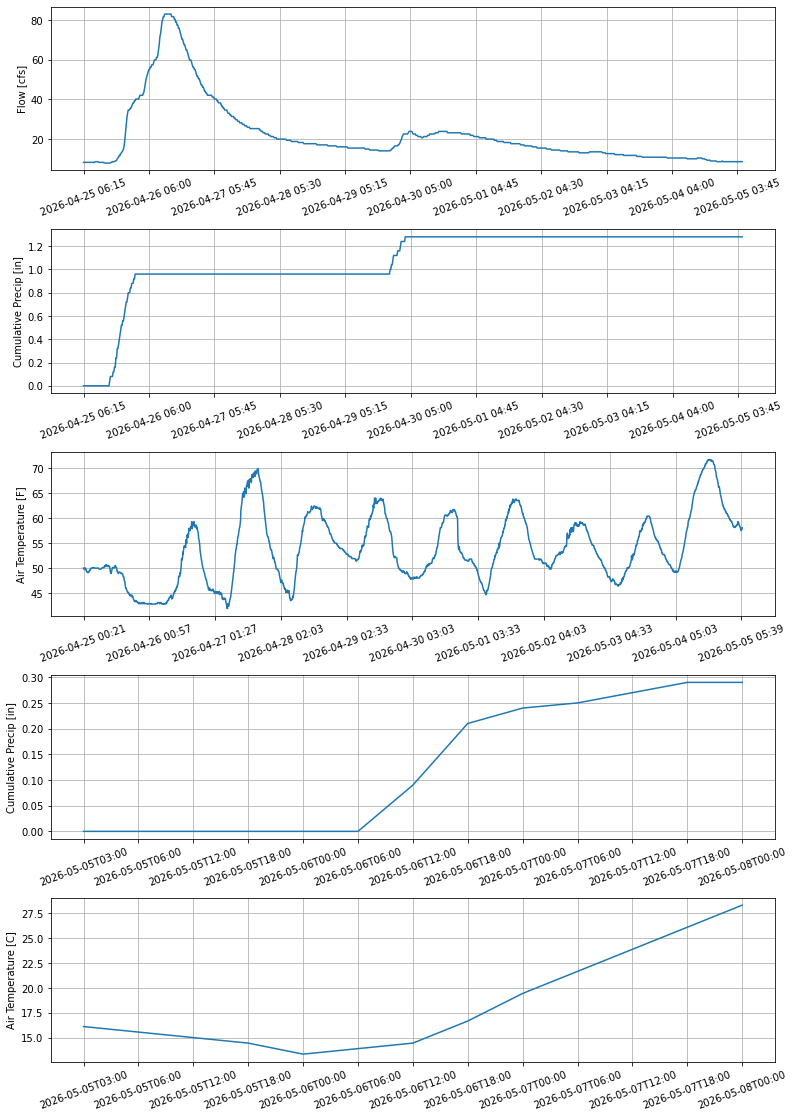

In [46]:
## plot data
## set up figure with 4 plots
fig, axs = plt.subplots(5,figsize=(12,16))

## plot past streamflow
axs[0].plot(StonyBrook['datetime_stony'],StonyBrook['flow_cfs'])
axs[0].set_xticks(StonyBrook['datetime_stony'][::len(StonyBrook['datetime_stony']) // 10])
axs[0].set_ylabel('Flow [cfs]')

## plot past precipitation
axs[1].plot(Skillman['datetime_skill'],Skillman['cum_precip_in'])
axs[1].set_xticks(Skillman['datetime_skill'][::len(Skillman['datetime_skill']) // 10])
axs[1].set_ylabel('Cumulative Precip [in]')

## plot past air temperature
axs[2].plot(Trenton['datetime_trent'],Trenton['airTemp_F'])
axs[2].set_xticks(Trenton['datetime_trent'][::len(Trenton['datetime_trent']) // 10])
axs[2].set_ylabel('Air Temperature [F]')

## plot forecast precip
axs[3].plot(data['DateTime'],data['cum_precip_in'])
axs[3].set_ylabel('Cumulative Precip [in]')

## plot forecast air temp
axs[4].plot(data['DateTime'],data['Temp [C]'])
axs[4].set_ylabel('Air Temperature [C]')

# put space between plots
fig.tight_layout(pad=4.0)

# add a grid and rotate the x-axis labels on each plot
for i in range(5):
    axs[i].grid()
    axs[i].tick_params(axis='x', labelrotation = 20)

## Precipitation Probability

In [47]:
## forecast for precipitation probability
headers = { 
'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/71.0.3578.98 Safari/537.36', 
'Accept' : 'text/html,application/xhtml+xml,application/xml;q=0.9,*/*;q=0.8', 
'Accept-Language' : 'en-US,en;q=0.5', 
'Accept-Encoding' : 'gzip', 
'DNT' : '1', # Do Not Track Request Header 
'Connection' : 'close' }
url = requests.get("https://api.weather.gov/gridpoints/PHI/63,95/", headers=headers)

data_json = json.loads(url.text)

data_prob = pd.DataFrame(columns=('DateTime','ProbPrecip [%]'))
for i in range(26):
    data_prob.loc[i] = [data_json['properties']['probabilityOfPrecipitation']['values'][i]['validTime'], 
                   data_json['properties']['probabilityOfPrecipitation']['values'][i]['value']]
 
data_prob['DateTime'] = data_prob['DateTime'].str.slice(stop=16)

# Merge forecasted precipitation with probability !
precip_and_prob = pd.merge(data[['DateTime', 'Precip [mm]']], data_prob)

print('Forecasted Data')
print(precip_and_prob)

Forecasted Data
            DateTime Precip [mm] ProbPrecip [%]
0   2026-05-05T03:00           0              0
1   2026-05-05T06:00           0              1
2   2026-05-05T12:00           0              2
3   2026-05-06T00:00           0              1
4   2026-05-06T12:00       2.286             59
5   2026-05-06T18:00       3.048             81
6   2026-05-07T00:00       0.762             69
7   2026-05-07T06:00       0.254             39
8   2026-05-07T12:00       0.508             49
9   2026-05-07T18:00       0.508             39
10  2026-05-08T00:00           0             20


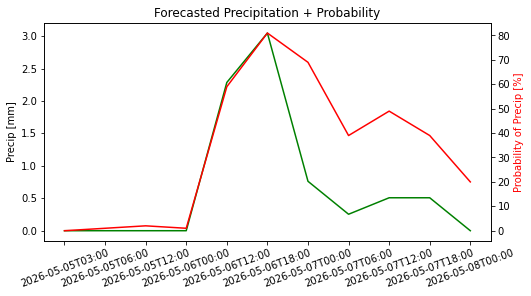

In [48]:
fig, ax = plt.subplots(figsize=(8,4))

ax.plot(precip_and_prob['DateTime'],precip_and_prob['Precip [mm]'], color='g')
ax2=ax.twinx()
ax2.plot(precip_and_prob['DateTime'],precip_and_prob['ProbPrecip [%]'], color='r')
ax.tick_params(axis='x', labelrotation = 20)
ax.set_ylabel('Precip [mm]')
ax.set_title('Forecasted Precipitation + Probability')
ax2.set_ylabel('Probability of Precip [%]',color='red')
plt.show()

## Streamflow Forecast and Evaluation

### Forecast Model and Implementation

In [73]:
## Code goes here in as many cells as you need

## Q1.1, DAYMET URL
url = "https://daymet.ornl.gov/single-pixel/send/saveData?lat=40.3573&lon=-74.6672&start=2024-04-01&end=2024-05-01&format=csv"

# read in the data much like before
weather = pd.read_csv(url, skiprows=6)
weather.head()

,year,yday,dayl (s),prcp (mm/day),srad (W/m^2),swe (kg/m^2),tmax (deg c),tmin (deg c),vp (Pa)
0,2024,92,45005.24,11.81,160.49,0.0,10.23,5.43,898.43
1,2024,93,45168.12,36.38,95.18,0.0,8.46,5.89,927.68
2,2024,94,45330.68,37.37,56.82,0.0,6.29,5.17,882.66
3,2024,95,45492.88,4.87,298.39,0.0,11.64,2.19,714.84
4,2024,96,45654.69,0.00,322.79,0.0,9.86,2.77,745.10


Mean ET0 over past 10 days: 2.93 mm/day = 0.1154 in/day
NSE   = 0.655
PBIAS = 25.3%
RMSE  = 9.4 cfs


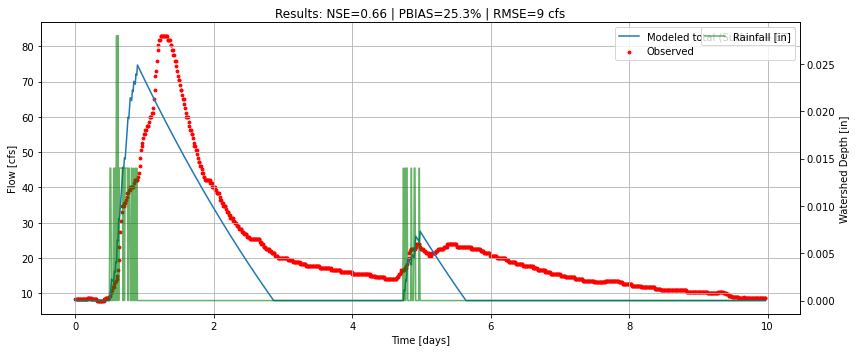

In [70]:

#1. GET ET (reusing HW2 code, fixed)
#ET is treated as a climatological mean loss term, not soil-moisture limited evaporation


today = datetime.datetime.today()
start_et = (today - datetime.timedelta(days=10)).strftime('%Y-%m-%d')
end_et = today.strftime('%Y-%m-%d')
url_et = f"https://daymet.ornl.gov/single-pixel/send/saveData?lat=40.3573&lon=-74.6672&start={start_et}&end={end_et}&format=csv"
weather = pd.read_csv(url_et, skiprows=6)

T_min = weather['tmin (deg c)']
T_max = weather['tmax (deg c)']
T_mean = (T_min + T_max) / 2

# constants
u2     = 2
albedo = 0.23
sigma  = 4.903e-9
a_s    = 0.25
b_s    = 0.55
gamma  = 0.066

# solar geometry
J = pd.to_datetime(weather['year']*1000 + weather['yday'], format='%Y%j').dt.dayofyear
phi = np.deg2rad(40.3573)
G_sc = 0.0820
d_r       = 1 + 0.033 * np.cos(2*np.pi*J/365)
delta_solar = 0.409 * np.sin(2*np.pi*J/365 - 1.39)
omega_s   = np.arccos(-np.tan(phi) * np.tan(delta_solar))
R_a       = (24*60/np.pi) * G_sc * d_r * (
    omega_s * np.sin(phi) * np.sin(delta_solar) +
    np.cos(phi) * np.cos(delta_solar) * np.sin(omega_s)
)

# observed solar radiation
R_s  = weather['srad (W/m^2)'] * weather['dayl (s)'] / 1e6
R_so = (a_s + b_s) * R_a
R_ns = (1 - albedo) * R_s

def calc_e0(T):
    return 0.6108 * np.exp((17.27*T) / (T + 237.3))

e_a = calc_e0(T_min - 2)
R_nl = sigma * (
    ((T_max+273.16)**4 + (T_min+273.16)**4) / 2
) * (0.34 - 0.14*np.sqrt(e_a)) * (1.35*(R_s/R_so) - 0.35)
R_n = R_ns - R_nl

e_s          = (calc_e0(T_max) + calc_e0(T_min)) / 2
delta_vapor  = 4096 * e_s / (T_mean + 237.3)**2

ET0 = (
    0.408 * delta_vapor * R_n +
    gamma * (900 / (T_mean + 273)) * u2 * (e_s - e_a)
) / (delta_vapor + gamma * (1 + 0.34 * u2))

ET_in_per_day = ET0 * 0.0393701          # mm/day to in/day
ET_daily_avg  = float(np.mean(ET_in_per_day))  # single average
print(f"Mean ET0 over past 10 days: {np.mean(ET0):.2f} mm/day = {ET_daily_avg:.4f} in/day")


#2. PARAMETERS that we keep fixed


area      = 44.5 * 2.788e7   # ft^2
inches_per_foot = 12
dt        = 0.25 / 24        # 15-min timestep [days]
T_star    =  5         # surface residence time [days]
runoff_coeff = 0.35

n_tsteps = len(StonyBrook)
t        = np.arange(n_tsteps) * dt

# converting observed flow to watershed depth
StonyBrook['flow_cfs'] = pd.to_numeric(StonyBrook['flow_cfs'], errors='coerce')
StonyBrook['flow_in']  = StonyBrook['flow_cfs'] * inches_per_foot * 900 / area
q_obs = StonyBrook['flow_in'].values.astype(float)

# baseflow
#(even though we are not using GW, we can still consider some baseflow happening when dry season continues -  reusing from Forecast 1)
baseflow = np.nanmin(q_obs)
q_quick  = q_obs - baseflow
q_quick[q_quick < 0] = 0

# precipitation
Skillman['precip_in'] = pd.to_numeric(Skillman['precip_in'], errors='coerce').fillna(0)
P_series = Skillman['precip_in'].values
if len(P_series) < n_tsteps: #we need to make sure that the data row numbers match to each other
    P_series = np.pad(P_series, (0, n_tsteps - len(P_series)), 'constant')
else:
    P_series = P_series[:n_tsteps]

# effective rainfall after adding runoff coeff (just making it constant certain features that we are not modeling)
w = P_series * runoff_coeff
ET_per_ts = ET_daily_avg * dt

lag = 10   # in real life, obviously there is a time between rain happening and sensor water level recording. so we are assuming that in the model

w = np.roll(w, lag)
w[:lag] = 0.0   # zero-fill to avoid error

# 3. LINEAR RESERVOIR MODEL (NO GW)


Q_surf = np.zeros(n_tsteps)
V_surf = np.zeros(n_tsteps)

# initial conditions considering baseflow

V_surf[0] = q_quick[0] * T_star
Q_surf[0] = q_quick[0]

# model loop, minusing ET from storage - storage = prev storage + rain (after multiplied by runoff coeff) - ET
for i in range(1, n_tsteps):
    Q_surf[i] = V_surf[i-1] / T_star
    V_surf[i] = V_surf[i-1] + (w[i] - Q_surf[i] - ET_per_ts) * dt
    V_surf[i] = max(V_surf[i], 0)



# 4. TOTAL FLOW to CFS to have it on the graph


Q_total_in  = Q_surf + baseflow
Q_model_cfs = Q_total_in * area / (inches_per_foot * 900)
Q_obs_cfs   = q_obs * area / (inches_per_foot * 900)


# 5. VALIDATION METRICS: several of them


mask     = ~np.isnan(Q_obs_cfs) & ~np.isnan(Q_model_cfs)
obs_v    = Q_obs_cfs[mask]
mod_v    = Q_model_cfs[mask]
obs_mean = obs_v.mean()

NSE   = 1 - np.sum((obs_v - mod_v)**2) / np.sum((obs_v - obs_mean)**2)
PBIAS = 100 * np.sum(obs_v - mod_v) / np.sum(obs_v)
RMSE  = np.sqrt(np.mean((obs_v - mod_v)**2))

print(f"NSE   = {NSE:.3f}")
print(f"PBIAS = {PBIAS:.1f}%")
print(f"RMSE  = {RMSE:.1f} cfs")



# 6.  PLOT to compare observed flow vs the model

#Final forecast employs linear reservoir combined with ET 



t_obs = np.arange(len(StonyBrook)) * dt

fig, ax1 = plt.subplots(figsize=(12, 5))
ax1.scatter(t_obs, Q_obs_cfs, color='red', s=8, label='Observed')
ax1.plot(t, Q_model_cfs, label='Modeled total (Surface + ET)', linewidth=1.5)
ax1.set_xlabel('Time [days]')
ax1.set_ylabel('Flow [cfs]')
ax1.set_title(f'Results: NSE={NSE:.2f} | PBIAS={PBIAS:.1f}% | RMSE={RMSE:.0f} cfs')
ax1.legend()
ax1.grid()

ax2 = ax1.twinx()
ax2.plot(t, w, color='green', alpha=0.6, label='Rainfall [in]')
ax2.set_ylabel('Watershed Depth [in]')
ax2.legend()

plt.tight_layout()
plt.show()

Day 1: 8 cfs
Day 2: 9 cfs
Day 3: 8 cfs


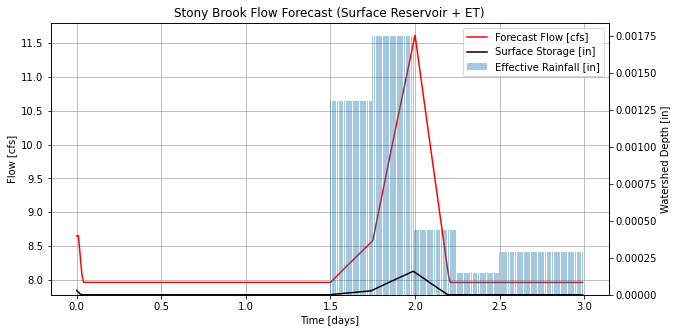

In [71]:
# FORECAST (SURFACE RESERVOIR + ET)

forecast_days = 3
n_tsteps_f    = int(forecast_days / dt)
time_forecast = np.arange(n_tsteps_f) * dt

# initializing to zero
V_f = np.zeros(n_tsteps_f)
q_f = np.zeros(n_tsteps_f)

# initial condition: last observed quick flow (baseflow already separated)
V_f[0] = q_quick[-1] * T_star
q_f[0] = q_quick[-1]

# forecast precipitation to effective rainfall (same method as before)
steps_per_row = int((6/24) / dt)   # NWS gives 6-hr intervals
forecast_precip = data['Precip_in'].values * runoff_coeff
w_f = np.repeat(forecast_precip / steps_per_row, steps_per_row)
w_f = w_f[:n_tsteps_f]

# subtracting ET per timestep
ET_per_ts = ET_daily_avg * dt

# Again the Euler linear reservoir — same loop as hindcast
for i in range(1, n_tsteps_f):
    q_f[i] = V_f[i-1] / T_star
    V_f[i] = V_f[i-1] + (w_f[i] - (q_f[i]) - ET_per_ts) * dt
    V_f[i] = max(V_f[i], 0)


# adding baseflow back, converting to cfs
q_f_cfs = (q_f + baseflow) * area / (inches_per_foot * 900)

# daily averages
steps_per_day = int(1 / dt)
day_names = ['Day 1', 'Day 2', 'Day 3']
for day in range(forecast_days):
    s = day * steps_per_day
    e = s + steps_per_day
    print(f"{day_names[day]}: {np.mean(q_f_cfs[s:e]):.0f} cfs")

# ploting the final predicted forecasted flow result
#(no precipitation, so it is horizontal, but if there was precipitation, it would have been exponential decay)

#So, right now it is staying nearly constant at the baseflow value that we found from the minimum observed from the past data. 
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.plot(time_forecast, q_f_cfs, color='red', label='Forecast Flow [cfs]')
ax1.set_xlabel('Time [days]')
ax1.set_ylabel('Flow [cfs]')
ax1.grid()

ax2 = ax1.twinx()
ax2.bar(time_forecast, w_f, width=dt*0.8, alpha=0.4, label='Effective Rainfall [in]')
ax2.plot(time_forecast, V_f, color='black', label='Surface Storage [in]')
ax2.set_ylabel('Watershed Depth [in]')

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2)
plt.title("Stony Brook Flow Forecast (Surface Reservoir + ET)")
plt.show()

**Tuesday:** `<8 cfs>` <br>
**Wednesday:** `<9 cfs>` <br>
**Thursday:** `<8 cfs>`

### Modeling Approach

`Answer: This code was made using a combination of ET estimation and the linear reservoir model in conjunction with the observed hydrometerological data for Stony Brook, an adaptation of our earlier work for Homework 2. For ET estimation, we once again employed the FAO-56 Penman-Monteith method, based on the past eleven days of flow, precipitation, and air temperature derived from USGS data from the Stony Brook, which is geographically located at a latitude of 40.3573 degrees and a longitude of -74.6672. The reference evapotranspiration was estimated using assumptions for set parameters: a mean wind speed of 2 meters per second (for 2 meters above the ground), an albedo of 0.23 (an appropriate assessment for the suburban areas bordering the Stony Brook which are covered by a mix of grassland, agrarian areas, and interspersed urban spaces), Angstrom constants of 0.25 and 0.55, and a psychometric constant of 0.66 kPa/K based on the heat capacity of air, atmospheric pressure, latent heat of vaporization, and ratio of molecular weight of water vapor to dry air. We thought these constants translated well for accuracy in our previous constant, and therefore utilized them again. Solar radiation data that factored into the calculation of the reference transpiration was derived from DAYMET data on solar radiation, temperature, and vapor pressure. While groundwater was not incorporated into this forecast, a baseflow was also incorporated through calculating the minimum observed flow. Then, the single-resevoir Euler formula with a surface resident time (T*) was collated with effective rainfall calculations to determine the projected streamflow. This T* accounts for the relative high proportion of natural environments in the Stony Brook watershed coupled with multiple stormwater management mechanisms that prevent rapid drainage of the basin. Hindcasts were validated with Skillman precipitation sourced from Trenton, while forecast precipitation data was derived from NWS.`

### Strengths and Limitations

`Answer: This forecast is strong through its basis in physical principles and quantitative calculations. In this forecast, our fundamental understanding of linear reservoir balances is reflected through a modified Euler linear reservoir. The methodology is enhanced through the incorporation of baseflow and effective rainfall calculations based on the datasets provided. In addition, its largest strength is manifested through the ET calculation, which incorporates incredibly granular calculations of water cycling through the environment through the consideration of physical factors including vapor pressure, time-dependent solar radiation, and other fluxes grounded in the datasets provided. The wealth in details and specific applications to agriculture contained in the FAO-56 approach contains lots of utility in considering a whole-environment projection of streamflow rather than the hydrology-only focused view of many models. This forecast also leverages our understanding of the physical and hydrological setting of the Stony Brook to select better-informed constants when calculation is not necessary. However, the abundance of constants despite this granularity serves as the forecast's greatest weakness and limitation. The approximation of many processes through constants, especially for particularly critical processes such as albedo, watershed response, and wind speed which are locationally dependent and often variant, impacts the accuracy and precision of the forecast. This also propagates through relatively informal calculations of baseflow compared to other forecasts which provide a more rigorous approach. However, the strength of ET and linear reservoir method provide it credibility against our previous forecasts. Forecast 3, which was based on machine learning, was promising due to its identification of patterns through convolutional  neural networks that had the potential to implicitly capture physical processes not relayed in our prior forecasts. However, because of its lack of physical basis, this produced flagrant error. The training of the model through inputs and epochs was not sufficient to match up against the physical basis of this current forecast. The thorough calculation of the ET through the FAO-56 method instead of a generalized constant of 0.8 in Forecast 1 enumerates clear benefits of this current forecast. Forecast 4, through virtue of its derivation from analytical and quantitative modeling rather than the guesses of Forecast 0, inevitably ensures stronger results. In addition, while Forecast 4 uses the same principles as Forecast 2, small refinements in the selection of constants, calculation of effective rainfall, and strengthening of the linear reservoir portion will likely produce a better forecast.`

### Comparison with Previous Forecasts

`Answer: We settled on the superior fit of this forecast both based on the rigor of the methodology discussed earlier and its prior success in Forecast 2. In Forecast 2, our RMSE for the forecast was only 1.074321 cfs, significantly lower than the RMSE values of 106, 65, and 23 for Forecasts 0, 2, 3 respectively. Furthermore, this forecast is significantly more grounded in water cycling principles to guide its modeling, especially in comparison to the pattern-based machine learning approach of Forecast 3, the oversimplification of water cycling in Forecast 1, and the guess-based reasoning of Forecast 0. In addition, we resolved to generally keep our iteration unaltered by future class material in context of the environment of the Stony Brook watershed and principles of hydrologic modeling. Groundwater, while pertinent to the watershed, changes in water balance over longer periods of time than the three day forecast allowed, leading us to settle on the methods of Forecast 2 to prevent potential propagations in error. The lack of snow in the season made snow-based modeling less appealing as snowmelt impacts diminish with the progression of the spring. In addition, the low grade in the Stony Brook watershed ruled out the incorporation of overland flow principles.`

### Model Validation

`Answer: Validation of the model was conducted through the Nash-Sutcliffe Efficiency, percent bias (PBIAS), and root means squared error (NSE). The standard employment of NSE led to its inevitable incorporation to evaluate model accuracy, but PBIAS gave us further insight on the directional bias of estimates, while RMSE helped us identify outliers that may have been indicative of specific errors in the model. Firstly, the validity of our model is reinforced by an NSE of 0.6+ in many combinations of different parameter values for our hindcast, which is “Satisfactory” according to many standards of hydrological evaluation and relatively close to 1, which would indicate perfect model fit. However, it does not constantly exceed the “Good” threshold of 0.6, indicating some model errors that may be attributed to the simplification of physical processing through constants. This assessment is reinforced by a PBIAS of 25.3%, indicative of systematic overestimates of hindcast data. The model appears to overcompensate streamflow reaction to precipitation. Finally, we have an RMSE of 9.4 cfs, meaning that the model is inaccurate by 9.4 cfs on average. This range of uncertainty, while significant, is small compared to our previous machine learning forecast, which possessed an RMSE of 218.98 cfs. These validation metrics allowed us to refine our linear reservoir and ET values, but much of the inaccuracy is expected due to the employment of constants whilst calculating stream flow in addition to the exclusion of concrete calculation of groundwater, snowmelt, and potential flow variance due to elevation grades.`

### Previous Forecast Metrics

`Answer: Previous forecasts used the same validation metrics, except for Forecast 3, which scored hydrological data using Kling-Gupta Efficiency instead of NSE. Kling-Gupta is often better for periodic data, so while we tested it in Forecast 3, the granularity of these forecasts led us to return to PBIAS. In addition, while Kling-Gupta could have helped remedy the deficits of NSE in overestimating peak flow, the PBIAS provided a somewhat clear interpretation of this through straightforward calculations of overestimation. Through an exposure and employment of different forecasting methods, we have certainly improved our skills in forecasting. The strength of rigorous calculation was displayed through the increases in efficiency progressing through Forecast 0 to Forecast 2, while the potential pitfalls of neural networks were made apparent to us through the significant inaccuracy of Forecast 3. These forecasts have displayed the significance of a utilization and understanding of hydrological principles in conjunction with technological modeling for accurate projections of data. Especially considering the relative simplicity of our watershed of study, our understanding of principles of water cycling improved our ability to interpret data and extrapolate such interpretations over granular periods. `

Acknowledgement: We did not utilize AI in this assignment as most codes were reused from previous assignments and needed only a bit of modification. 